# 03 · Modelling


Goal: six data science questions. All models train on 2021-2024 and are tested on 2025 (time-based split, no leakage). Code lives in `src/models.py`; this notebook runs it and shows the results.



In [1]:
# Setup: works from the project root or from notebooks/
import sys
from pathlib import Path
BASE = Path.cwd() if (Path.cwd() / "Data").exists() else Path.cwd().parent
sys.path.append(str(BASE / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from config import *
from theme import *
apply_theme()
make_dirs()
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.3f}".format)
from load import load_clean
import features as F
import models as M
clean = load_clean()
bf = F.booking_features(clean)

## 1. Cancellation prediction
Target: `status == 'Cancelled'`. Features are only things known at booking time (lead time, rate plan, channel, price vs competitors, guest's past behaviour ...). `status_datetime` is left out because it leaks the answer.

In [2]:
cx = M.cancellation_model(clean, bf)
pd.Series(cx["metrics"])

1. Cancellation model


   test_cancel_rate=0.156, auc_gradient_boosting=0.771, auc_logistic_baseline=0.771, pr_auc_gradient_boosting=0.369, brier_gradient_boosting=0.115, share_of_cancels_in_top20pct_risk=0.471


train_rows                          228,825.000
test_rows                            76,473.000
test_cancel_rate                          0.156
auc_gradient_boosting                     0.771
auc_logistic_baseline                     0.771
pr_auc_gradient_boosting                  0.369
brier_gradient_boosting                   0.115
share_of_cancels_in_top20pct_risk         0.471
dtype: float64

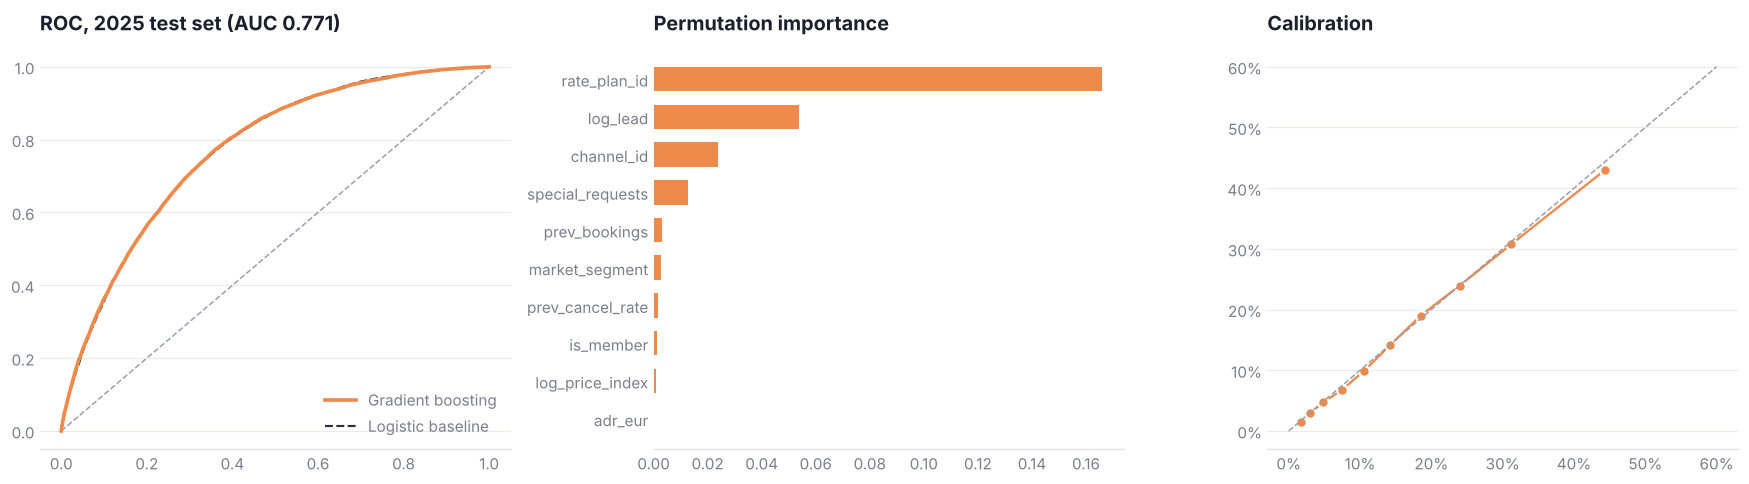

In [3]:
from sklearn.metrics import roc_curve
roc = pd.read_csv(TAB_DIR / "cancel_roc.csv")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for name, d in roc.groupby("model"):
    axes[0].plot(d.fpr, d.tpr, color=ORANGE if name == "Gradient boosting" else INK_2, lw=2.4 if name == "Gradient boosting" else 1.4, ls="-" if name == "Gradient boosting" else "--",
                 zorder=3 if name == "Gradient boosting" else 2, label=name)
axes[0].plot([0, 1], [0, 1], color=GREY, ls="--", lw=1); axes[0].legend(loc="lower right")
title(axes[0], f"ROC, 2025 test set (AUC {cx['metrics']['auc_gradient_boosting']:.3f})")
imp = cx["importance"].head(10).iloc[::-1]
axes[1].barh(imp.feature, imp.importance, color=ORANGE, height=0.65); axes[1].grid(axis="y", visible=False)
title(axes[1], "Permutation importance")
cal = cx["calibration"]
axes[2].plot(cal.predicted, cal.actual, "o-", color=ORANGE, mec=BG, mew=1.5, ms=7); axes[2].plot([0, .6], [0, .6], color=GREY, ls="--", lw=1)
fmt_axis(axes[2], "x"); fmt_axis(axes[2]); title(axes[2], "Calibration")
plt.tight_layout(); save_fig(fig, "03_cancellation_model"); plt.show()

**Business use:** the riskiest 20% of bookings hold almost half of all cancellations. Hotels can ask these guests for a deposit, send a reminder, or overbook a little on nights with many risky bookings. The logistic baseline scores the same AUC, so it is a good choice when the model must be explained to hotel managers.

## 2. Demand forecast
Target: occupancy per hotel per night. Features known a year ahead: calendar, holidays, city events, last year's occupancy, competitor prices. Baseline: same weekday last year.

In [4]:
fc = M.demand_forecast(clean)
pd.Series(fc["metrics"])

2. Demand forecast (rooms sold per hotel-night)


   wape_model=0.146, wape_naive_last_year=0.194, mae_rooms_model=4.321, wape_monthly_model=0.068


wape_model             0.146
wape_naive_last_year   0.194
mae_rooms_model        4.321
wape_monthly_model     0.068
dtype: float64

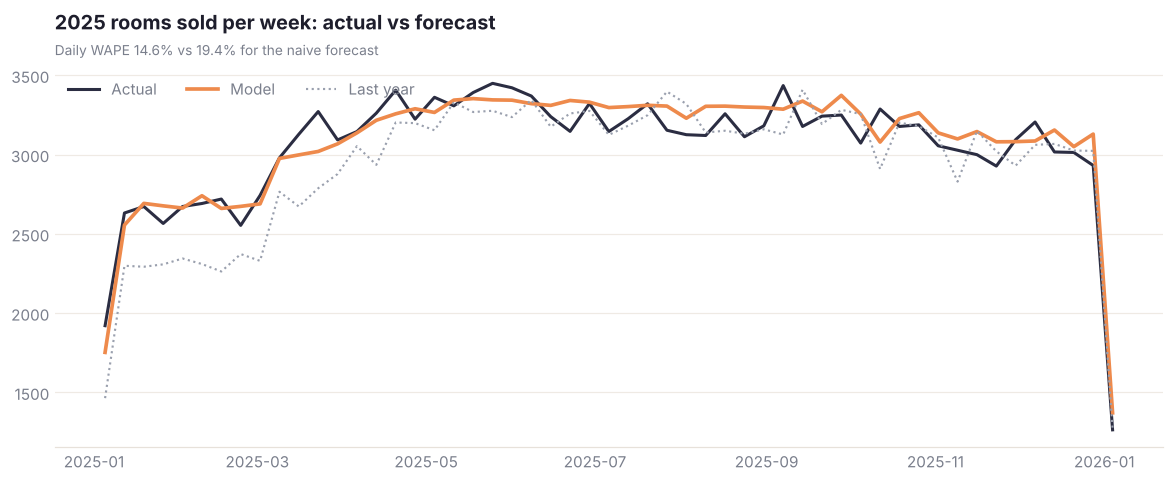

In [5]:
d = fc["daily"]; t = d[d.year == 2025]
w = t.groupby(pd.Grouper(key="date", freq="W"))[["rooms_sold", "forecast_rooms", "naive_rooms"]].sum()
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(w.index, w.rooms_sold, color=INK_2, lw=2, label="Actual")
ax.plot(w.index, w.forecast_rooms, color=ORANGE, lw=2.4, label="Model")
ax.plot(w.index, w.naive_rooms, color=GREY, lw=1.4, ls=":", label="Last year")
ax.legend(ncol=3, loc="upper left"); title(ax, "2025 rooms sold per week: actual vs forecast", f"Daily WAPE {fc['metrics']['wape_model']:.1%} vs {fc['metrics']['wape_naive_last_year']:.1%} for the naive forecast")
save_fig(fig, "03_demand_forecast"); plt.show()

In [6]:
fc["by_hotel"].sort_values("wape_model")

,hotel_id,actual_rooms,forecast_rooms,wape_model,wape_naive
7,H08,"16,774.000","16,388.700",0.105,0.138
5,H06,"12,516.000","12,440.300",0.118,0.180
3,H04,"15,084.000","14,497.000",0.120,0.155
9,H10,"8,668.000","8,309.100",0.126,0.172
10,H11,"10,044.000","9,736.500",0.127,0.162
6,H07,"12,291.000","11,863.900",0.127,0.168
2,H03,"10,703.000","10,790.300",0.129,0.186
1,H02,"10,795.000","10,543.600",0.132,0.193
0,H01,"11,490.000","11,406.500",0.137,0.199
11,H12,"9,648.000","9,585.600",0.139,0.191


## 3. Price elasticity
Observational data is biased: after July 2023 the revenue management system raises prices exactly when demand is high. The A/B price test (EXP02) randomly showed prices 8% lower or higher, which gives a clean causal estimate.

In [7]:
pr = M.pricing_analysis(clean)
pd.Series(pr["metrics"])

3. Pricing analysis


   logit_coef_price_observational=-1.815, logit_coef_price_experiment=-1.924, arc_elasticity_conversion_exp02=-1.385


logit_coef_price_observational    -1.815
logit_coef_price_experiment       -1.924
arc_elasticity_conversion_exp02   -1.385
dtype: float64

In [8]:
pr["by_variant"]

,variant,quotes,conversion,avg_price,revenue_per_quote
0,control,10924,0.255,226.202,136.186
1,price_minus_8,10924,0.283,205.904,142.233
2,price_plus_8,10894,0.227,244.347,131.954


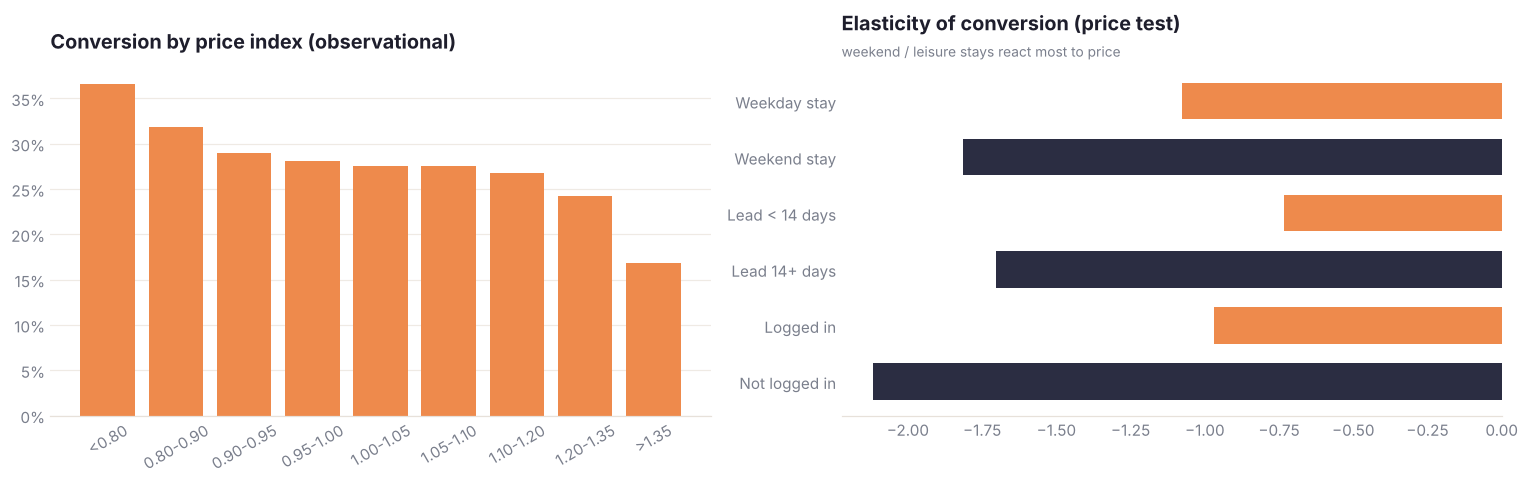

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
c = pr["curve"]
axes[0].bar(c.price_bin.astype(str), c.conversion, color=ORANGE); fmt_axis(axes[0]); axes[0].tick_params(axis="x", rotation=30)
title(axes[0], "Conversion by price index (observational)")
g = pr["by_group"]
axes[1].barh(g.group, g.elasticity, color=[INK_2 if e < -1.5 else ORANGE for e in g.elasticity], height=0.65); axes[1].invert_yaxis(); axes[1].grid(axis="y", visible=False)
title(axes[1], "Elasticity of conversion (price test)", "weekend / leisure stays react most to price")
plt.tight_layout(); save_fig(fig, "03_pricing"); plt.show()

**Business use:** demand is elastic (about -1.4, more than 1 in absolute terms), so in the price test the -8% arm earned more room revenue per quote than control and the +8% arm earned less. Weekday stays are much less sensitive (about -1.1), so a smarter policy is to keep weekday prices and use targeted discounts for weekend leisure stays.

## 4. A/B tests

In [10]:
ab = M.ab_tests(clean)
ab[["experiment_id", "experiment_name", "variant", "control_conv", "variant_conv", "diff_pp", "ci_low_pp", "ci_high_pp", "p_value", "significant"]]

4. A/B tests
experiment_id       variant  diff_pp  p_value
        EXP01  new_checkout    3.162    0.000
        EXP02 price_minus_8    2.810    0.000
        EXP02  price_plus_8   -2.821    0.000
        EXP03         badge    3.207    0.000
        EXP04       urgency    0.028    0.970


,experiment_id,experiment_name,variant,control_conv,variant_conv,diff_pp,ci_low_pp,ci_high_pp,p_value,significant
0,EXP01,Checkout page redesign,new_checkout,0.233,0.264,3.162,1.771,4.553,0.000,True
1,EXP02,Price test (-8% / +8%),price_minus_8,0.255,0.283,2.810,1.635,3.985,0.000,True
2,EXP02,Price test (-8% / +8%),price_plus_8,0.255,0.227,-2.821,-3.955,-1.688,0.000,True
3,EXP03,Member price badge,badge,0.271,0.303,3.207,2.051,4.363,0.000,True
4,EXP04,Urgency message 'Only X rooms left',urgency,0.286,0.286,0.028,-1.406,1.462,0.970,False


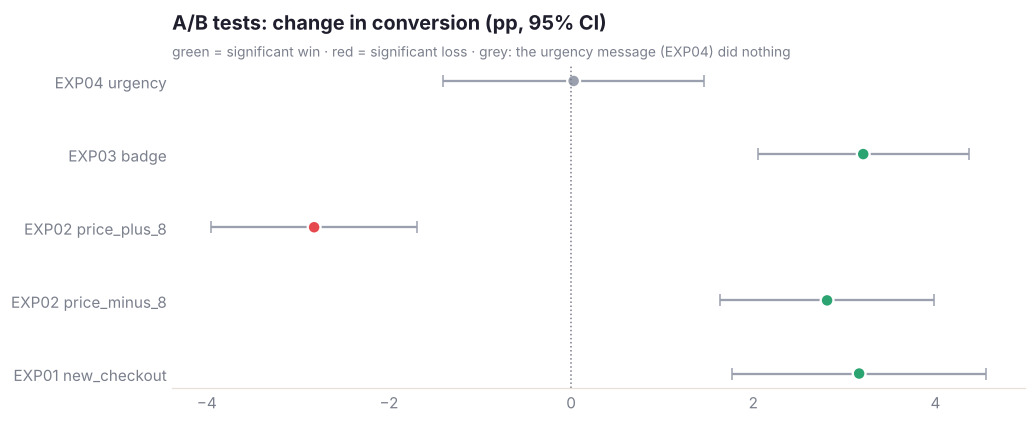

In [11]:
fig, ax = plt.subplots(figsize=(10, 3.8))
lab = ab.experiment_id + " " + ab.variant
col = [GREEN if s and v > 0 else (RED if s else GREY) for s, v in zip(ab.significant, ab.diff_pp)]
ax.errorbar(ab.diff_pp, lab, xerr=[ab.diff_pp - ab.ci_low_pp, ab.ci_high_pp - ab.diff_pp], fmt="none", ecolor=GREY, capsize=4, zorder=1)
ax.scatter(ab.diff_pp, lab, color=col, s=70, edgecolor=BG, linewidth=1.5, zorder=2)
ax.axvline(0, color=TEXT_MUTED, lw=1, ls=":"); ax.grid(axis="y", visible=False)
title(ax, "A/B tests: change in conversion (pp, 95% CI)", "green = significant win · red = significant loss · grey: the urgency message (EXP04) did nothing")
save_fig(fig, "03_ab_tests"); plt.show()

## 5. What drives review scores

In [12]:
rd = M.review_drivers(clean, bf)
rd["coefs"]

5. Review score drivers


   R2 = 0.245


,driver,effect,ci_low,ci_high
10,Group trip,-0.260,-0.292,-0.227
0,Staff turnover (+1 pp),-0.229,-0.231,-0.226
11,Event in city,-0.215,-0.234,-0.195
8,Business trip,-0.188,-0.199,-0.175
1,Price vs competitors (+10%),-0.129,-0.131,-0.125
12,Long stay (7+ nights),-0.124,-0.155,-0.101
9,Family trip,-0.084,-0.104,-0.059
5,Superior room,0.144,0.134,0.157
3,Breakfast included,0.155,0.142,0.169
4,Member rate,0.162,0.139,0.179


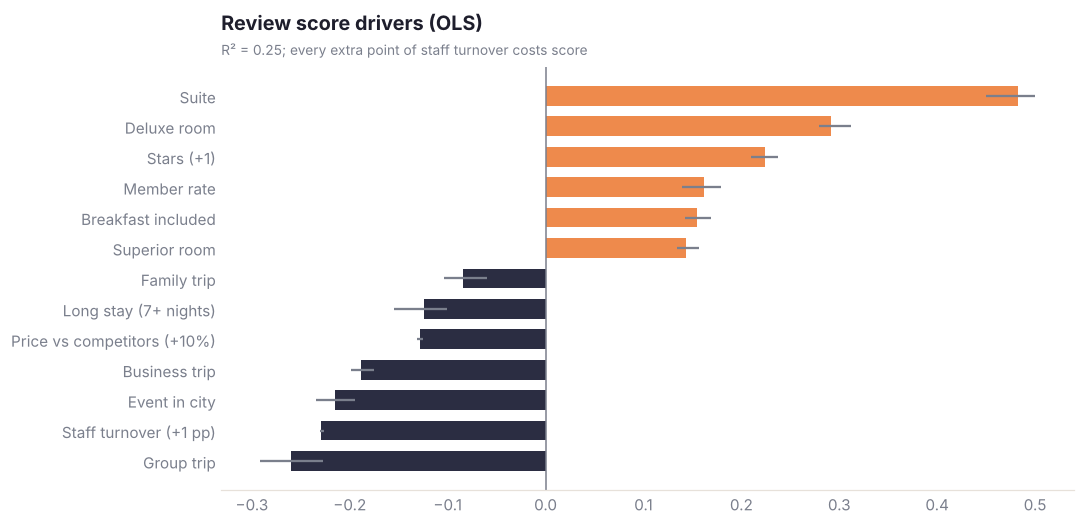

In [13]:
cf = rd["coefs"]
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(cf.driver, cf.effect, xerr=[cf.effect - cf.ci_low, cf.ci_high - cf.effect], color=[ORANGE if v > 0 else INK_2 for v in cf.effect], ecolor=TEXT_MUTED, height=0.65)
ax.axvline(0, color=TEXT_MUTED, lw=1); ax.grid(axis="y", visible=False)
title(ax, "Review score drivers (OLS)", f"R² = {rd['r2']:.2f}; every extra point of staff turnover costs score")
save_fig(fig, "03_review_drivers"); plt.show()

In [14]:
rd["phrases"].sort_values("mentions", ascending=False).head(15)

,phrase,mentions,avg_score,tone
13,Great neighbourhood,8445,8.211,Positive
34,Walking distance to everything,8376,8.212,Positive
20,Perfect location,8308,8.185,Positive
21,"Quiet room, slept well",6205,8.659,Positive
16,Lovely room design,6069,8.667,Positive
33,Very comfortable bed,6065,8.673,Positive
15,Housekeeping was excellent,5804,8.722,Positive
25,Spotless room,5771,8.742,Positive
10,Fair price for the quality,5746,8.681,Positive
32,Very clean and fresh,5714,8.727,Positive


## 6. Guest segments (K-means)

In [15]:
sg = M.guest_segments(clean, bf)
sg["profiles"].set_index("segment").round(2)

6. Guest segments (K-means)


              segment  guests  bookings  value_per_guest  share_of_value
       Direct bookers   46615     1.010          452.110           0.160
Cancel-prone planners   39757     1.030            9.320           0.000
       Loyal regulars   37674     2.710        1,017.390           0.290
       OTA one-timers   73180     1.030          412.330           0.230
    Families & groups   34667     1.150        1,176.570           0.310


,cluster,guests,bookings,cancel_rate,total_value,avg_lead,avg_nights,avg_party,weekday_share,direct_share,recency_days,value_per_guest,value_total,share_of_value
segment,,,,,,,,,,,,,,
Direct bookers,0,46615,1.010,0.010,452.110,33.840,2.220,1.770,0.560,1.000,630.660,452.110,"21,074,953.830",0.160
Cancel-prone planners,1,39757,1.030,1.000,9.320,56.120,2.700,2.100,0.540,0.210,848.170,9.320,"370,568.570",0.000
Loyal regulars,2,37674,2.710,0.150,"1,017.390",30.330,2.280,1.640,0.620,0.520,426.370,"1,017.390","38,329,327.600",0.290
OTA one-timers,3,73180,1.030,0.010,412.330,31.500,2.130,1.740,0.560,0.000,829.140,412.330,"30,174,432.080",0.230
Families & groups,4,34667,1.150,0.040,"1,176.570",74.730,4.400,3.110,0.480,0.330,709.860,"1,176.570","40,788,178.400",0.310


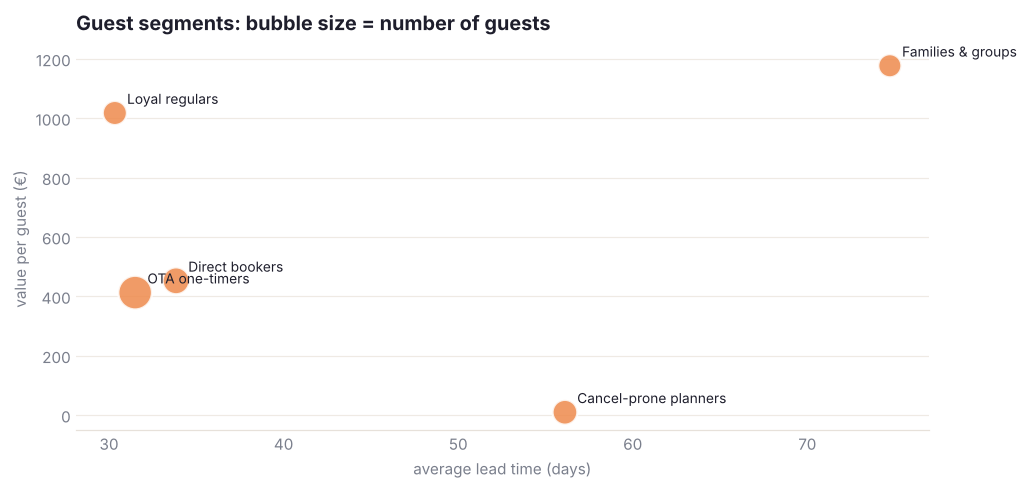

In [16]:
p = sg["profiles"]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.scatter(p.avg_lead, p.value_per_guest, s=p.guests / 150, color=ORANGE, alpha=0.85, edgecolor=BG, linewidth=1.5)
for r in p.itertuples():
    ax.annotate(r.segment, (r.avg_lead, r.value_per_guest), xytext=(8, 6), textcoords="offset points", color=TEXT, fontsize=9)
ax.set_xlabel("average lead time (days)"); ax.set_ylabel("value per guest (€)")
title(ax, "Guest segments: bubble size = number of guests")
save_fig(fig, "03_guest_segments"); plt.show()

## Summary
| Question | Result |
|---|---|
| Who cancels? | AUC ≈ 0.77 on 2025 for both gradient boosting and logistic regression (the signal is mostly linear, so the simple model is enough); top 20% risk holds ≈ 47% of cancels |
| How many rooms will we sell? | Daily WAPE ≈ 15% vs 19% naive; monthly WAPE ≈ 7% |
| How price sensitive are guests? | Elasticity ≈ -1.4 overall, weekend stays most sensitive |
| Which tests worked? | New checkout and member badge: yes; urgency message: no |
| What drives reviews? | Room type, value for money and staff turnover |
| Who are our guests? | 5 segments; loyal regulars (29%) and families & groups (31%) bring most value |

Next: the results in `output/tables/` feed the Streamlit dashboard. Start it with `cd streamlit_app` and `streamlit run app.py`.